# Problem

Quantify seven mineral phases in **eight physically prepared, measured powder-XRD mixtures**. Each includes known20wt% corundum. Recover mass fractions, angular offsets and all3001 modeled count samples per mixture. Independent weighed compositions are actual ground truth for fractions; original R outputs are method references for registration and fitted curves.

The source calls these “synthetic mixtures”, meaning physically manufactured samples, not simulated diffraction. The selected scope is the paper's known-seven-standard full-pattern summation experiment. Its separate automatic identification from a169-pattern library is outside this fixed-candidate task and is not claimed as reproduced.

In [1]:
from pathlib import Path
import sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,natural_spline
from src.solvers import reconstruct
from src.physics_model import rwp
from src.visualization import composition_rmse,observation_rwp
plt.rcParams.update({'font.size':10,'axes.grid':True,'grid.alpha':.2})
data=load_data(ROOT/'data/raw_data.npz'); angle=data['angles']
names=['Corundum','Quartz','Microcline','Labradorite','Kaolinite','Illite','Smectite']
with np.load(ROOT/'evaluation/ground_truth.npz') as f: truth=f['reconstruction'][0]
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz') as f: native={k:f[k] for k in f.files}
print('Measured patterns',data['counts'].shape,'pure-phase calibration',data['standards'].shape)
print('Truth is independently weighed composition; curves and shifts have only method references.')

Measured patterns (8, 3001) pure-phase calibration (3001, 7)
Truth is independently weighed composition; curves and shifts have only method references.


# Data

The eight full scans cover5–65degrees2theta in0.02degree increments under Cu K-alpha radiation. Seven pure-phase calibration patterns were measured independently, normalized to peak10000 and paired with reference intensity ratios. The reference library used a Siemens D500; no exact individual-mixture instrument log is invented. Corundum was physically added at20wt%.

No known unknown-phase concentration or presence mask is passed to the solver. Every candidate remains available for every mixture. The displayed truth is loaded only after data acquisition for hidden maintainer validation.

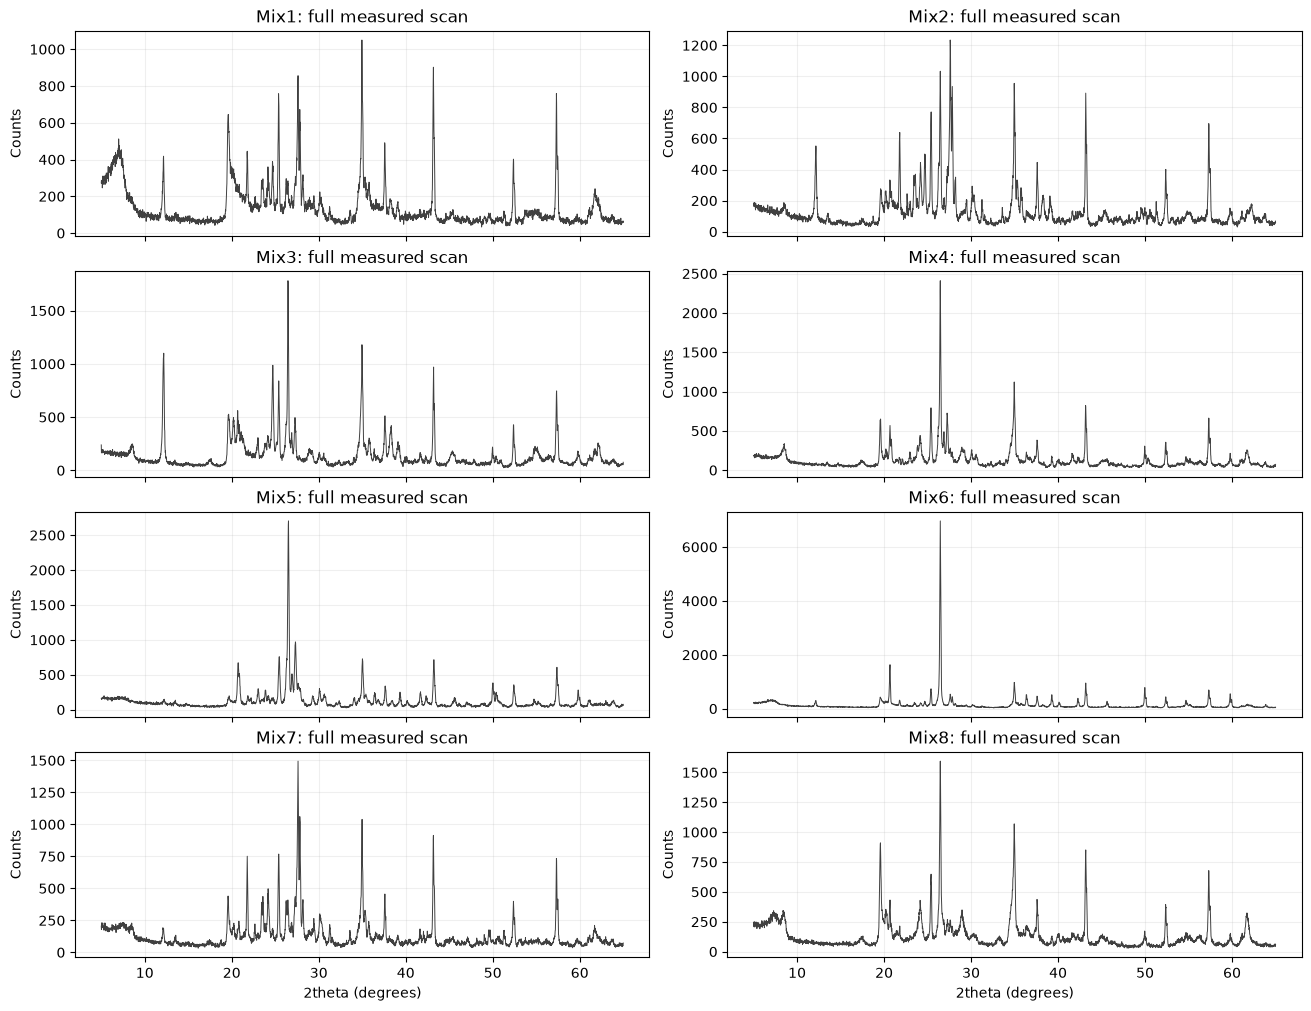

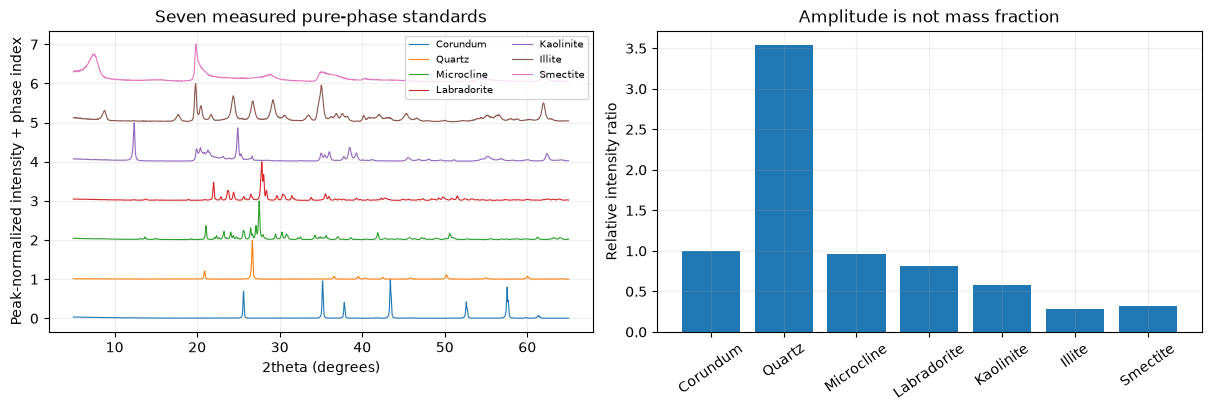

In [2]:
fig,ax=plt.subplots(4,2,figsize=(13,10),sharex=True,layout='constrained')
for i,a in enumerate(ax.flat):
    a.plot(angle,data['counts'][i],lw=.7,color='0.25'); a.set(title=f'Mix{i+1}: full measured scan',ylabel='Counts')
for a in ax[-1]: a.set_xlabel('2theta (degrees)')
plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for j,name in enumerate(names): ax[0].plot(angle,data['standards'][:,j]/10000+j,label=name,lw=.8)
ax[0].set(xlabel='2theta (degrees)',ylabel='Peak-normalized intensity + phase index',title='Seven measured pure-phase standards'); ax[0].legend(fontsize=7,ncol=2)
ax[1].bar(names,data['rir']); ax[1].tick_params(axis='x',rotation=35); ax[1].set(ylabel='Relative intensity ratio',title='Amplitude is not mass fraction')
plt.show()

# Physics

Let $q=2\theta$ denote diffraction angle in degrees. A rigid angular offset $\delta_m$ maps mixture $m$ to the standard coordinate system. Given measured pure-phase patterns $a_j$, the intensity model is

$$y_m(q)\simeq\sum_{j=0}^{6}c_{mj}a_j(q+\delta_m),\qquad c_{mj}\geq0.$$

Here $y$ is count intensity and $c$ the dimensionless pattern amplitude. Peak overlap and broad disordered scattering correlate the amplitudes. If $r_j$ is the independently calibrated relative intensity ratio and phase0 is corundum, then

$$X_{mj}=20\frac{c_{mj}}{c_{m0}}\frac{r_0}{r_j},\qquad r_0=1.$$

$X$ is weight percent. Calibrated estimates need not sum exactly to100; closing them to100 is a distinct comparison, not an invisible correction. Their error can reflect counting noise, standard mismatch, crystal orientation or correlated clay signatures.

# Method

Register each complete scan to corundum by minimizing one minus Pearson correlation over offsets within0.3degrees. Natural cubic interpolation uses linear extrapolation at endpoints. On the complete overlapping aligned grid, minimize

$$R_{\rm wp}(c)=\sqrt{\frac{\sum_k(y_k-(Ac)_k)^2/y_k}{\sum_k y_k}}.$$

$A$ contains the interpolated standard columns and $k$ enumerates angles. The production BFGS implementation preserves the original central0.001 coefficient differences, identity initialization, Armijo backtracking with0.2 reduction, inverse-Hessian update, restart rules and100-iteration limit. Negative coefficients trigger phase removal and refitting from surviving values. No true phase concentration controls removal.

For comparison we actively solve unweighted nonnegative least squares with a local active set. The original paper recommends BFGS/Rwp for quantitative fractions and NNLS primarily for fast phase identification. Every final curve is mapped back to all original3001 measured angles; this is the declared output coordinate convention.

In [3]:
start=time.perf_counter(); fresh,diag=reconstruct(data); bfgs_seconds=time.perf_counter()-start
start=time.perf_counter(); nnls,nn_diag=reconstruct(data,method='NNLS'); nnls_seconds=time.perf_counter()-start
no_align,na_diag=reconstruct(data,max_shift=0)
closed=fresh['reconstruction'][0]/fresh['reconstruction'][0].sum(axis=1,keepdims=True)*100
(ROOT/'output').mkdir(exist_ok=True); np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
proc=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert proc.returncode==0,proc.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text())
print('Fresh BFGS seconds:',bfgs_seconds,'fresh NNLS seconds:',nnls_seconds,'Judge:',report['status'])
print('All production optimization passes converged:',all(p['converged'] for d in diag for p in d['history']))
print('Fresh BFGS fraction max difference from original:',np.max(abs(fresh['reconstruction']-native['BFGS_reconstruction'])))
print('Fresh NNLS fraction max difference from original:',np.max(abs(nnls['reconstruction']-native['NNLS_reconstruction'])))

Fresh BFGS seconds: 0.10927640000591055 fresh NNLS seconds: 0.041399599984288216 Judge: pass
All production optimization passes converged: True
Fresh BFGS fraction max difference from original: 0.0
Fresh NNLS fraction max difference from original: 0.0


# Results

All eight measured patterns and residuals are shown, including mixtures with absent-phase estimates and clay confusion. Fresh results are computed above; dashed original-method quantities are independent references, not truth. Only the weighed compositions establish composition accuracy.

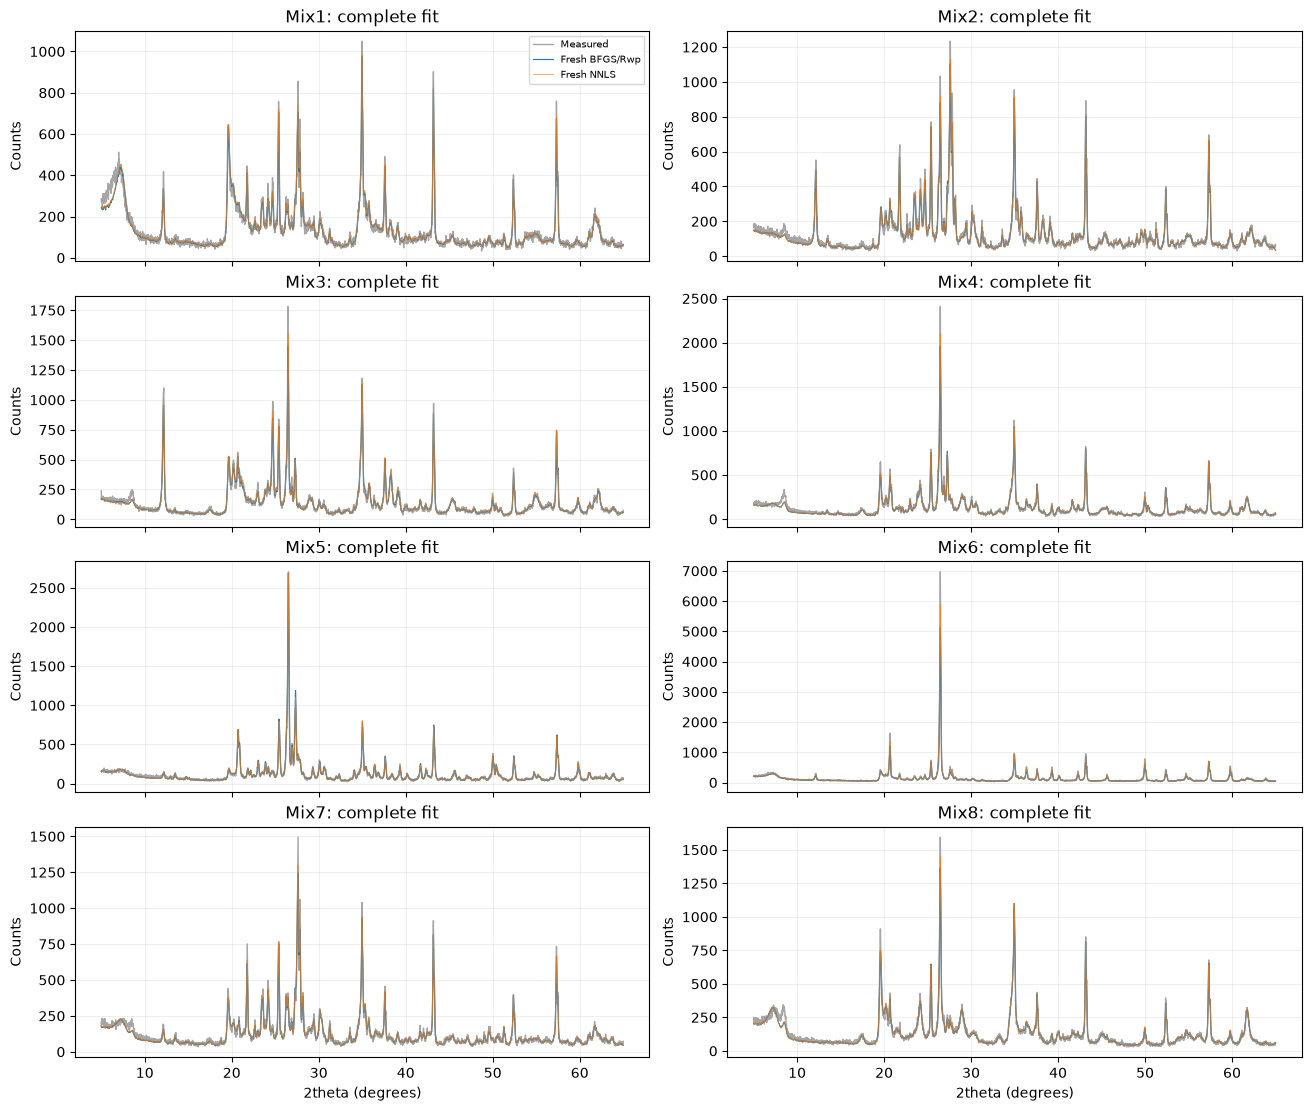

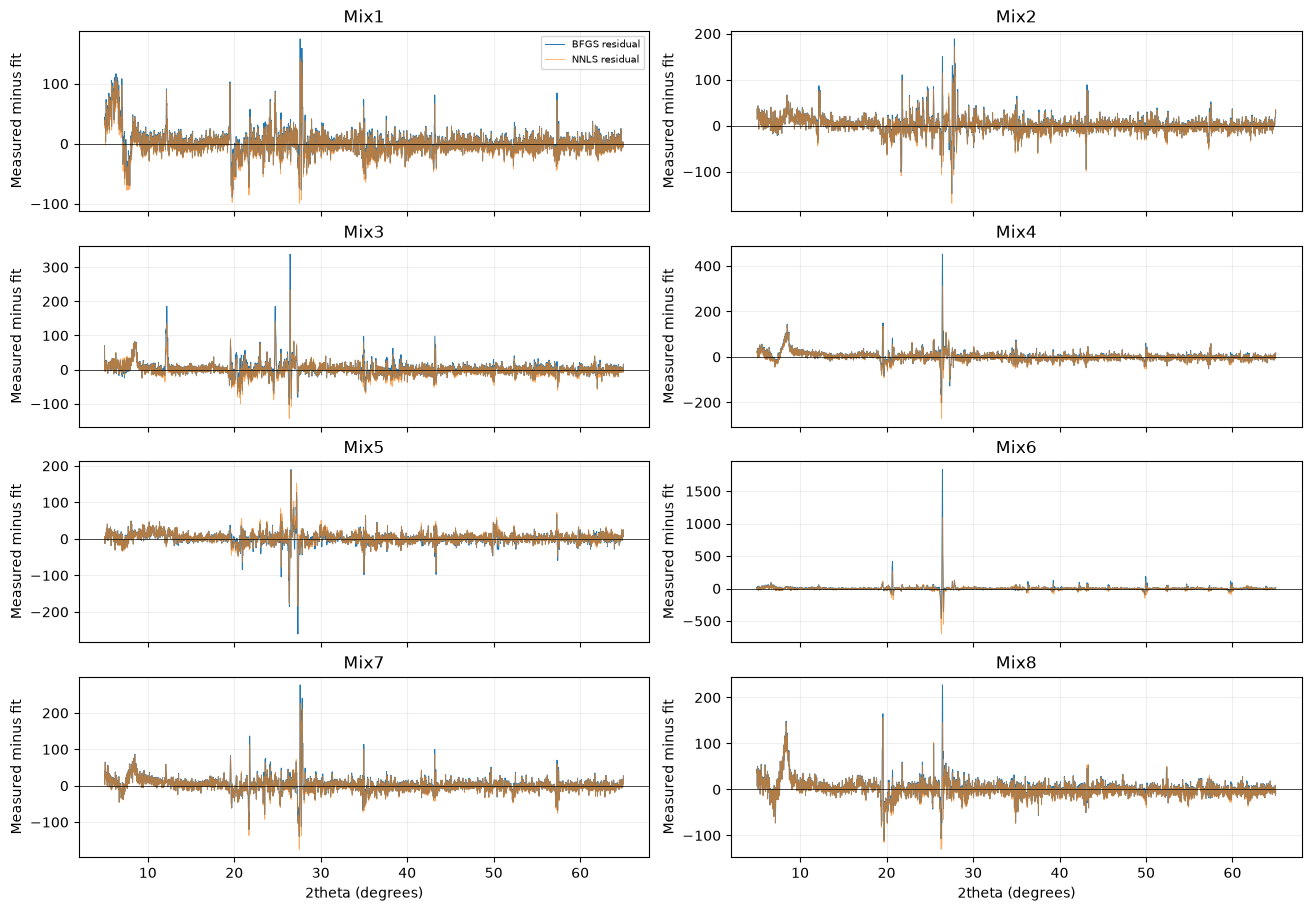

In [4]:
fig,ax=plt.subplots(4,2,figsize=(13,11),sharex=True,layout='constrained')
for i,a in enumerate(ax.flat):
    a.plot(angle,data['counts'][i],color='0.65',lw=1,label='Measured')
    a.plot(angle,fresh['fitted'][0,i],color='C0',lw=.8,label='Fresh BFGS/Rwp')
    a.plot(angle,nnls['fitted'][0,i],color='C1',lw=.6,alpha=.75,label='Fresh NNLS')
    a.set(title=f'Mix{i+1}: complete fit',ylabel='Counts')
ax[0,0].legend(fontsize=7)
for a in ax[-1]: a.set_xlabel('2theta (degrees)')
plt.show()
fig,ax=plt.subplots(4,2,figsize=(13,9),sharex=True,layout='constrained')
for i,a in enumerate(ax.flat):
    a.plot(angle,data['counts'][i]-fresh['fitted'][0,i],lw=.7,label='BFGS residual')
    a.plot(angle,data['counts'][i]-nnls['fitted'][0,i],lw=.6,alpha=.65,label='NNLS residual')
    a.axhline(0,color='k',lw=.5); a.set(title=f'Mix{i+1}',ylabel='Measured minus fit')
ax[0,0].legend(fontsize=7)
for a in ax[-1]: a.set_xlabel('2theta (degrees)')
plt.show()

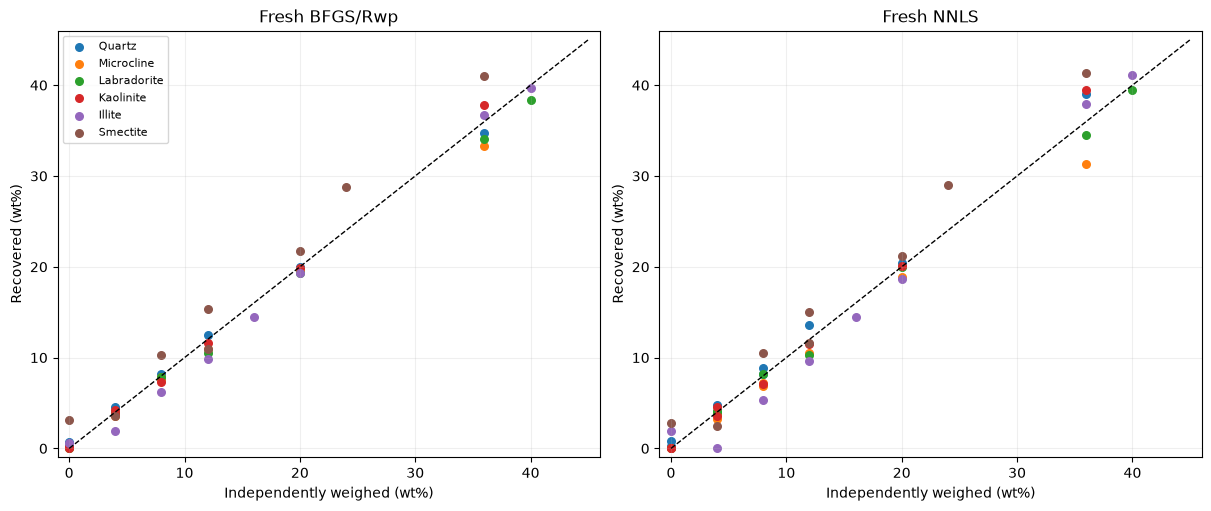

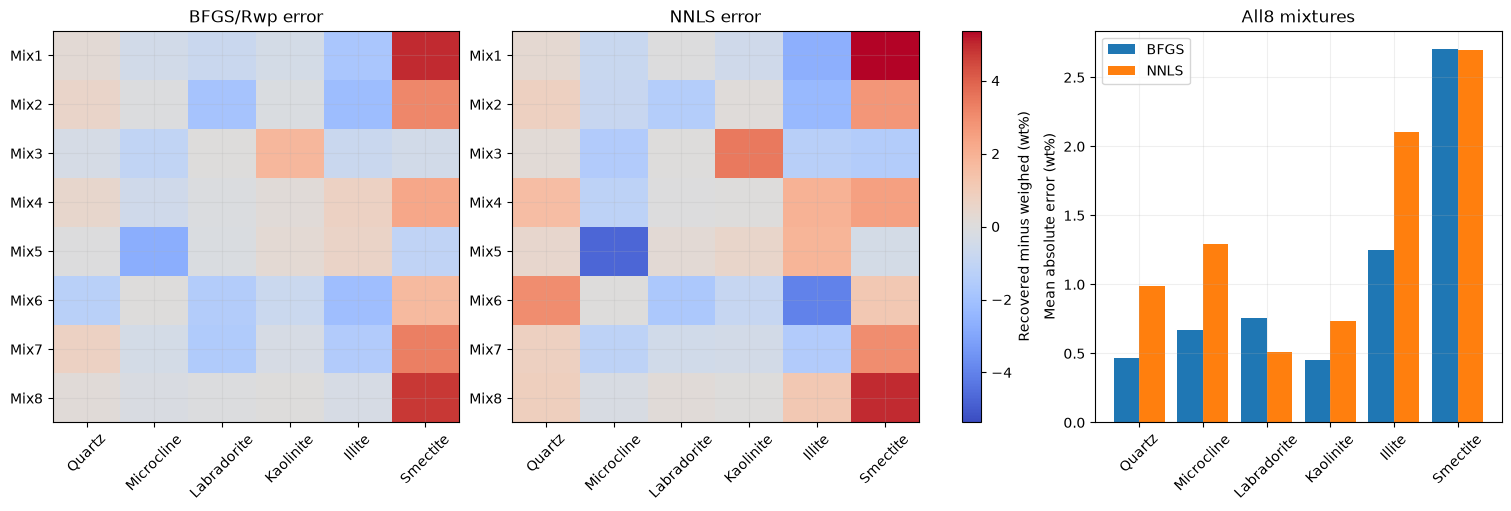

In [5]:
fig,ax=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for j,name in enumerate(names[1:],1):
    ax[0].scatter(truth[:,j],fresh['reconstruction'][0,:,j],s=30,label=name)
    ax[1].scatter(truth[:,j],nnls['reconstruction'][0,:,j],s=30,label=name)
for a,title in zip(ax,['Fresh BFGS/Rwp','Fresh NNLS']):
    a.plot([0,45],[0,45],'k--',lw=1); a.set(xlabel='Independently weighed (wt%)',ylabel='Recovered (wt%)',title=title,xlim=(-1,46),ylim=(-1,46))
ax[0].legend(fontsize=8)
plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,5),layout='constrained')
err1=fresh['reconstruction'][0,:,1:]-truth[:,1:]; err2=nnls['reconstruction'][0,:,1:]-truth[:,1:]
lim=max(np.max(abs(err1)),np.max(abs(err2)))
for a,e,title in zip(ax[:2],[err1,err2],['BFGS/Rwp error','NNLS error']):
    im=a.imshow(e,vmin=-lim,vmax=lim,cmap='coolwarm',aspect='auto'); a.set(xticks=range(6),xticklabels=names[1:],yticks=range(8),yticklabels=[f'Mix{i}' for i in range(1,9)],title=title); a.tick_params(axis='x',rotation=45)
fig.colorbar(im,ax=ax[:2],label='Recovered minus weighed (wt%)')
x=np.arange(6); ax[2].bar(x-.2,np.mean(abs(err1),axis=0),.4,label='BFGS'); ax[2].bar(x+.2,np.mean(abs(err2),axis=0),.4,label='NNLS'); ax[2].set(xticks=x,xticklabels=names[1:],ylabel='Mean absolute error (wt%)',title='All8 mixtures'); ax[2].tick_params(axis='x',rotation=45); ax[2].legend()
plt.show()

The next figures retain the paper's logic of comparing all measured mixtures with known compositions while distinguishing numerical parity from physical accuracy. The historical manuscript reports approximately0.9wt% mean error for its own closed-composition example; that number is not substituted for this20wt%-calibrated experiment. Closure below is computed from the fresh amplitudes as a labeled alternative.

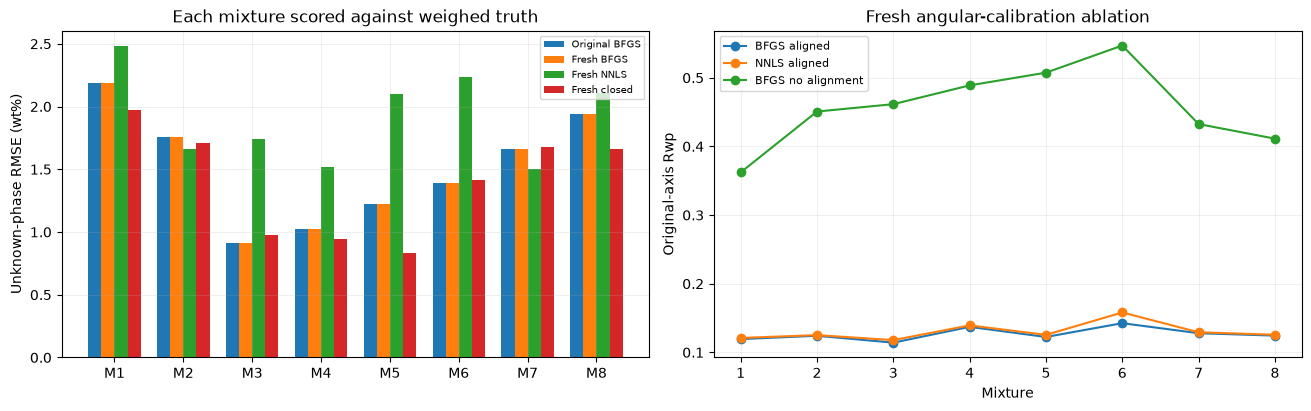

Original BFGS mean absolute unknown-phase error: 1.0494291666666669
Fresh BFGS mean absolute unknown-phase error: 1.0494291666666669
Fresh NNLS mean absolute unknown-phase error: 1.3878916666666667
Fresh closed mean absolute unknown-phase error: 1.0147568716324924
Calibrated composition sums: [101.8383  99.3753  99.2674 103.0603  96.9104  96.1103 100.3017 104.3723]


In [6]:
methods={'Original BFGS':native['BFGS_reconstruction'][0],'Fresh BFGS':fresh['reconstruction'][0],'Fresh NNLS':nnls['reconstruction'][0],'Fresh closed':closed}
fig,ax=plt.subplots(1,2,figsize=(13,4),layout='constrained'); x=np.arange(8)
for j,(name,value) in enumerate(methods.items()): ax[0].bar(x+(j-1.5)*.19,composition_rmse(value,truth),.19,label=name)
ax[0].set(xticks=x,xticklabels=[f'M{i}' for i in range(1,9)],ylabel='Unknown-phase RMSE (wt%)',title='Each mixture scored against weighed truth'); ax[0].legend(fontsize=7)
for label,result in [('BFGS aligned',fresh),('NNLS aligned',nnls),('BFGS no alignment',no_align)]: ax[1].plot(np.arange(1,9),observation_rwp(result['fitted'][0],data['counts']),'o-',label=label)
ax[1].set(xlabel='Mixture',ylabel='Original-axis Rwp',title='Fresh angular-calibration ablation'); ax[1].legend(fontsize=8)
plt.show()
for name,value in methods.items(): print(name,'mean absolute unknown-phase error:',np.mean(abs(value[:,1:]-truth[:,1:])))
print('Calibrated composition sums:',fresh['reconstruction'][0].sum(axis=1))

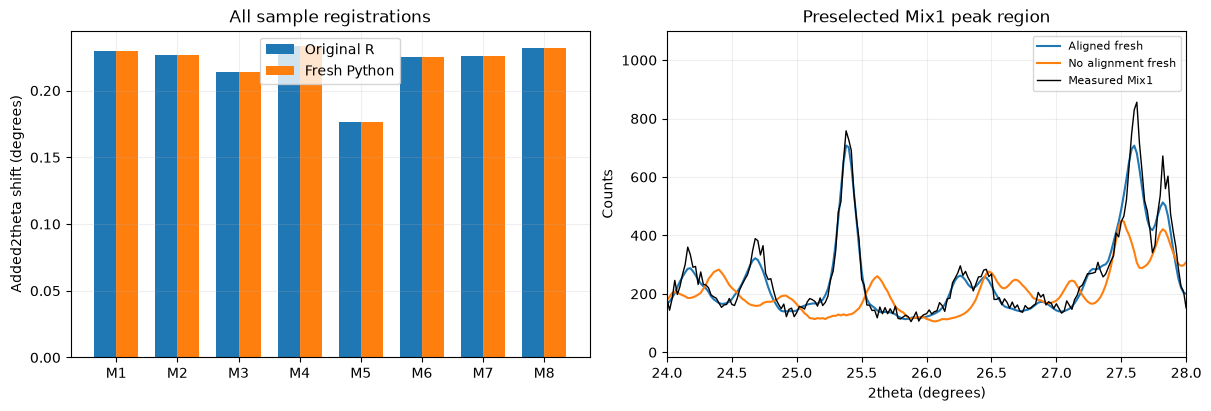

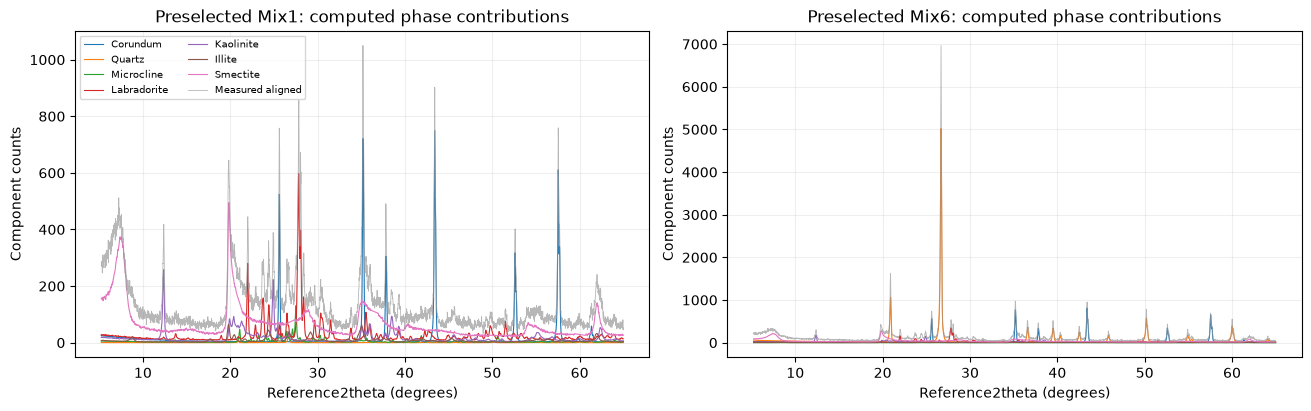

In [7]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
x=np.arange(8); ax[0].bar(x-.18,native['shifts'][0],.36,label='Original R'); ax[0].bar(x+.18,fresh['shifts'][0],.36,label='Fresh Python'); ax[0].set(xticks=x,xticklabels=[f'M{i}' for i in range(1,9)],ylabel='Added2theta shift (degrees)',title='All sample registrations'); ax[0].legend()
for label,result in [('Aligned fresh',fresh),('No alignment fresh',no_align)]: ax[1].plot(angle,result['fitted'][0,0],label=label)
ax[1].plot(angle,data['counts'][0],color='k',lw=1,label='Measured Mix1'); ax[1].set(xlim=(24,28),xlabel='2theta (degrees)',ylabel='Counts',title='Preselected Mix1 peak region'); ax[1].legend(fontsize=8)
plt.show()
fig,ax=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for a,i in zip(ax,[0,5]):
    d=diag[i]
    for j,name in enumerate(names): a.plot(d['grid'],d['matrix'][:,j]*d['coefficients'][j],label=name,lw=.8)
    a.plot(d['grid'],d['aligned'],color='0.6',lw=.6,alpha=.7,label='Measured aligned')
    a.set(xlabel='Reference2theta (degrees)',ylabel='Component counts',title=f'Preselected Mix{i+1}: computed phase contributions')
ax[0].legend(fontsize=7,ncol=2)
plt.show()

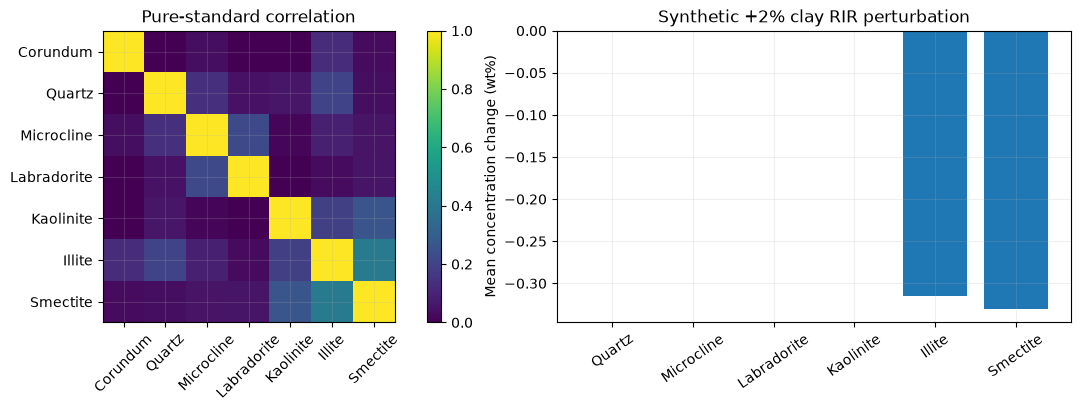

Maximum native/fresh profile discrepancy: 6.478119178154884e-05
Maximum native/fresh shift discrepancy: 8.318466804269065e-09


In [8]:
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
corr=np.corrcoef(data['standards'].T)
im=ax[0].imshow(corr,vmin=0,vmax=1,cmap='viridis'); ax[0].set(xticks=range(7),xticklabels=names,yticks=range(7),yticklabels=names,title='Pure-standard correlation'); ax[0].tick_params(axis='x',rotation=45); fig.colorbar(im,ax=ax[0])
# Calibration perturbation is supplementary and explicitly synthetic.
modified=data['rir'].copy(); modified[5:]*=1.02
sensitive=fresh['reconstruction'][0]*data['rir'][None,:]/modified[None,:]
ax[1].bar(names[1:],np.mean(sensitive[:,1:]-fresh['reconstruction'][0,:,1:],axis=0)); ax[1].tick_params(axis='x',rotation=35); ax[1].set(ylabel='Mean concentration change (wt%)',title='Synthetic +2% clay RIR perturbation')
plt.show()
print('Maximum native/fresh profile discrepancy:',np.max(abs(fresh['fitted']-native['BFGS_fitted'])))
print('Maximum native/fresh shift discrepancy:',np.max(abs(fresh['shifts']-native['shifts'])))

# Conclusion

The fresh local pipeline reproduces original BFGS/Rwp quantitative fitting and the NNLS comparison across all eight measured mixtures. The standalone Judge also checks actual weighed composition, angular registration, complete fitted profiles, observation residuals and fraction/profile consistency. No mixture is removed because it has a difficult clay composition.

Physical accuracy remains limited by overlap, clay-standard similarity and measurement/model mismatch. Known internal-standard calibration and artificial closure produce different estimates, and neither eliminates false-positive absent phases. The synthetic RIR perturbation illustrates calibration sensitivity without replacing real observations. Results support this fixed-seven-phase full-pattern inverse, not unrestricted phase discovery or a general crystal-structure refinement.